In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score
from sklearn.tree import DecisionTreeRegressor,plot_tree
from sklearn.compose import make_column_transformer,make_column_selector
from sklearn.preprocessing import OneHotEncoder
from tqdm import tqdm
import matplotlib.pyplot as plt
import os
os.chdir('E:/Machine_Learning/Cases/Concrete_Strength/')

In [3]:
df = pd.read_csv('Concrete_Data.csv')
df.head()

,Cement,Blast,Fly,Water,Superplasticizer,Coarse,Fine,Age,Strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [4]:
X,y=df.drop('Strength',axis=1),df['Strength']

In [5]:
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=42,test_size=0.3)
depths = [None,2,3,4,5,6,7]
min_split = [2,0.05,0.01,0.1,0.2,0.3]
min_leaf = [1,0.05,0.01,0.1,0.2,0.3]
scores = []
for d in tqdm(depths):
    for s in min_split:
        for f in min_leaf:
            dtr = DecisionTreeRegressor(random_state=26,max_depth=d,min_samples_split=s,min_samples_leaf=f)
            dtr.fit(X_train,y_train)
            y_pred = dtr.predict(X_test)
            scores.append([d,s,f,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Depth','Min_sample_splits','Min_sample_leaf','r2'])
df_scores.sort_values(by='r2',ascending=False)

100%|██████████| 7/7 [00:01<00:00,  5.54it/s]


,Depth,Min_sample_splits,Min_sample_leaf,r2
12,NaN,0.01,1.00,0.818644
0,NaN,2.00,1.00,0.811359
14,NaN,0.01,0.01,0.804244
2,NaN,2.00,0.01,0.804244
216,7.0,2.00,1.00,0.802379
...,...,...,...,...
227,7.0,0.05,0.30,0.197063
233,7.0,0.01,0.30,0.197063
239,7.0,0.10,0.30,0.197063
245,7.0,0.20,0.30,0.197063


In [6]:
X_train,X_test,y_train,y_test=train_test_split(X,y,random_state=26,test_size=0.3)
depths = [None,2,3,4,5,6,7]
min_split = [2,5,10,20,50]
min_leaf = [1,5,10,20,50]
scores = []
for d in tqdm(depths):
    for s in min_split:
        for f in min_leaf:
            dtr = DecisionTreeRegressor(random_state=26,max_depth=d,min_samples_split=s,min_samples_leaf=f)
            dtr.fit(X_train,y_train)
            y_pred = dtr.predict(X_test)
            scores.append([d,s,f,r2_score(y_test,y_pred)])
df_scores = pd.DataFrame(scores,columns=['Depth','Min_sample_splits','Min_sample_leaf','r2'])
df_scores.sort_values(by='r2',ascending=False)

100%|██████████| 7/7 [00:00<00:00,  7.65it/s]


,Depth,Min_sample_splits,Min_sample_leaf,r2
0,NaN,2,1,0.850026
5,NaN,5,1,0.841783
15,NaN,20,1,0.807598
12,NaN,10,10,0.799514
7,NaN,5,10,0.799514
...,...,...,...,...
35,2.0,10,1,0.512617
34,2.0,5,50,0.512617
48,2.0,50,20,0.512617
49,2.0,50,50,0.512617


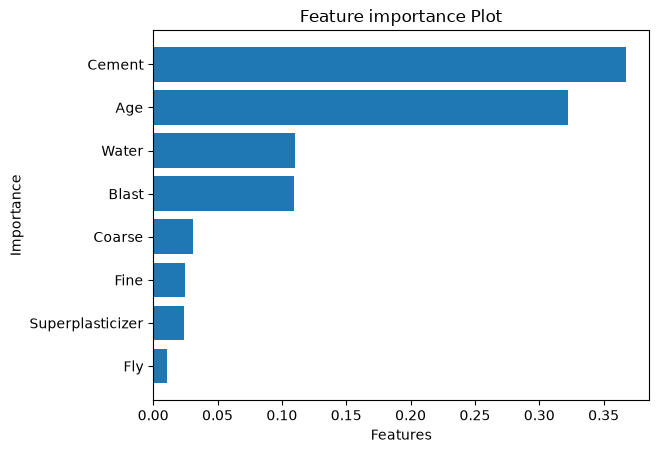

In [7]:
best_tree = DecisionTreeRegressor(random_state=26,min_samples_split=5,min_samples_leaf=1)
best_tree.fit(X,y)
df_imp = pd.DataFrame(
    {'features':list(X.columns),
    'importance' : best_tree.feature_importances_}
                     )
df_imp.sort_values('importance',inplace=True)
plt.barh(df_imp['features'],df_imp['importance'])
plt.title('Feature importance Plot')
plt.xlabel('Features')
plt.ylabel('Importance')
plt.show()